# Western Balkan Studies - LANDs plots

## Define RUN TAG

In [1]:
DATESTAMP='20261116'

In [2]:
# RUN_ID = 'vre_low_we2023_20260324'
RUN_ID='VRElow'
WEATHER_YEAR=str(2025)
SCENARIO_CFG_PATH='config/WB6/scenarios/baseline.yaml'

* load packages

In [3]:
import warnings
from datetime import datetime
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray as rxr

import RESource.visuals as vis
from RESource import utility as utils
from RESource.hdf5_handler import DataHandler
from RESource.gaez import load_gaez_raster
from RESource import lands
ROOT=utils.get_root()
plt.style.use(ROOT/'src/RESource/visual_styles/elsevier.mplstyle')
# Suppress specific warnings
warnings.filterwarnings("ignore", category=UserWarning)


- Load Configs

In [4]:
CFG_PATH = SCENARIO_CFG_PATH
cfg, cfg_provenance = utils.resolve_config(ROOT / CFG_PATH)

In [5]:
# cfg was resolved through the scenario's extends declaration above.
# run_id:str=cfg.get('Scenario').get('run_id')

sub_national_unit_tag: str = (
    cfg["admin_boundary"]["GADM"]["datafield_mapping"].get("NAME_2")
    or cfg["admin_boundary"]["GADM"]["datafield_mapping"].get("NAME_1")
)
country_name:str=cfg.get('country')
country_kwd=country_name.replace(' ','')
CRS_m = cfg.get('default_CRS').get('meters')  # Default metric CRS
CRS_d = cfg.get('default_CRS').get('degrees')  # Default geographic CRS
regions=list(cfg.get('region_mapping').keys()) #'AL','BA','XK','ME','MK','RS'
output_id = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
results_save_to_root = ROOT / 'results' / country_kwd / RUN_ID / f'Combined_lands_{output_id}'
results_save_to_root.mkdir(parents=True, exist_ok=False)
vis_save_to_root = utils.ensure_path(results_save_to_root / 'figures')
print(f'Output directory: {results_save_to_root}')

Output directory: /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839


In [6]:
import json
# Create a single, self-describing combined store for this RUN_ID.
# Config, provenance and runtime info travel with the data itself so the
# store stands on its own as input for the downstream dashboard.
run_tag = f"{RUN_ID}_{WEATHER_YEAR}_{DATESTAMP}"
combined_store_root = ROOT / 'data/store' / country_kwd / 'Combined'
combined_store_root.mkdir(parents=True, exist_ok=True)
combined_store_path = combined_store_root / f"resources_{country_kwd}_Combined_{run_tag}.h5"
combined_datahandler = DataHandler(combined_store_path)
if combined_store_path.exists():
    if combined_datahandler.get_metadata('config') != json.loads(json.dumps(cfg, default=str)):
        raise ValueError(f'Combined store configuration differs from the selected config: {combined_store_path}')
    import h5py
    land_keys = ['boundary_combined', 'existing_VREs_by_CLC_landcover', 'CLC_class_distribution',
        'existing_VREs_by_GAEZ_terrain', 'existing_VREs_by_GAEZ_exclusion', 'transmission_lines_combined']
    land_images = [f'country_map_{country_kwd}', 'existing_VREs_by_landcover', 'CLC_class_distribution',
        'CLC_developable_land_and_VREs', 'GAEZ_terrains_class_distribution', 'existing_VREs_by_terrain',
        'GAEZ_terrain_developable_land_and_VREs', 'GAEZ_exclusion_class_distribution',
        'existing_VREs_by_exclusions', 'GAEZ_exclusion_developable_land_and_VREs', 'grid_lines_and_existing_VREs']
    with h5py.File(combined_store_path, 'r') as store:
        existing = [f'LandAnalytics/{key}' for key in land_keys if f'LandAnalytics/{key}' in store]
        existing += [f'LandAnalytics/images/{key}' for key in land_images if f'LandAnalytics/images/{key}' in store]
    if existing:
        raise FileExistsError(f'Land analytics already exist in {combined_store_path}: {existing}')
else:
    combined_datahandler.set_metadata({
    "config": cfg,
    "config_provenance": cfg_provenance,
    "runtime": utils.get_runtime_info(),
    "run_id": run_tag,
    "weather_year": WEATHER_YEAR,
    "datestamp": DATESTAMP,
    "country": country_name,
    "regions": regions,
    })
utils.print_update(level=1, message=f"Combined store ready: {combined_store_path}")

  └> RESource.hdf5_handler| 💾 Metadata (['config', 'config_provenance', 'runtime', 'run_id', 'weather_year', 'datestamp', 'country', 'regions']) written to '_meta' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5
└> Combined store ready: /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


## Load Store

In [7]:
 #All the regions should have RUN_ID results available
combined_store:dict[dict] = {}
utils.print_update(level=1,message=f"Loading data stores for {country_name} regions with RUN_ID: {RUN_ID} and Regions: {regions}")
for region in regions:
    country_dict = {}
    store = ROOT / 'data/store' / country_kwd / region / f'resources_{country_kwd}_{region}_{run_tag}.h5'
    if not store.is_file():
        raise FileNotFoundError(f'Regional store not found: {store}')
    res_data = DataHandler(store, show_structure=False)
    country_dict['capacity_haircut'] = res_data.get_metadata('capacity_haircut')
    for name, key in [('cells', 'cells'), ('boundary', 'boundary'), ('lines', 'lines')]:
        country_dict[name] = res_data.from_store(key)
        if country_dict[name] is None:
            raise ValueError(f'Cannot load {key} from regional store {store}')
    combined_store[region] = country_dict
    utils.print_update(level=2, message=f"Loaded data for {cfg['region_mapping'][region]['name']}.")

from RESource.store_analytics import store_combined_capacity_haircuts
# Older stores without metadata use the previously selected WB6 notebook factors.
fallback_haircut = {'solar': 0.8, 'wind': 0.6}
haircut = store_combined_capacity_haircuts(combined_datahandler,
    {region: data['capacity_haircut'] for region, data in combined_store.items()}, fallback_haircut)
print(f'Capacity haircut factors: {haircut}; raw stored capacity columns remain unchanged.')

└> Loading data stores for Western Balkan Regions regions with RUN_ID: VRElow and Regions: ['AL', 'BA', 'XK', 'ME', 'MK', 'RS']
 └> ✓ Loaded data for : Albania.
 └> ✓ Loaded data for : Bosnia and Herzegovina.
 └> ✓ Loaded data for : Kosovo.
 └> ✓ Loaded data for : Montenegro.
 └> ✓ Loaded data for : North Macedonia.
 └> ✓ Loaded data for : Serbia.


## Load All Cells

In [8]:
all_cells_dict:dict[pd.DataFrame]=[combined_store[region]['cells'] for region in combined_store]
all_cells_gdf = gpd.GeoDataFrame(pd.concat(all_cells_dict, ignore_index=False), crs=all_cells_dict[0].crs)

# Load Test/Validation data

In [9]:
existing_VREs_data_path=Path(ROOT/"data/validation_data/existing_VREs_WB6.csv")
if existing_VREs_data_path.exists():
    existing_VREs=pd.read_csv(existing_VREs_data_path)
    existing_VREs_gdf=gpd.GeoDataFrame(existing_VREs,geometry=gpd.points_from_xy(existing_VREs.Longitude,existing_VREs.Latitude),crs="EPSG:4326")
    utils.print_update(level=1,message=f"✓ Loaded validation data for existing VREs from {existing_VREs_data_path}")
else:
    existing_VREs_gdf=None
    utils.print_warning(f"Validation data for existing VREs not found at {existing_VREs_data_path}")

└> ✓ Loaded validation data for existing VREs from /local-scratch/localhome/mei3/eliasinul/work/RESource/data/validation_data/existing_VREs_WB6.csv


# Lands

- Prepare Combined Regional boundary

In [ ]:
# Combine all region boundaries into a single GeoDataFrame
boundary_gdfs = [combined_store[region]['boundary'] for region in combined_store]
all_boundary_gdf = gpd.GeoDataFrame(pd.concat(boundary_gdfs, ignore_index=True), crs=boundary_gdfs[0].crs)
all_boundary_dissolved = all_boundary_gdf.dissolve(by="Country")[["geometry"]].reset_index()


- Process the boundary info for raster plotting

In [111]:
COUNTRY_TO_ISO2={
    "Albania": "AL",
    "Bosnia and Herzegovina": "BA",
    "Kosovo": "XK",
    "Montenegro": "ME",
    "North Macedonia": "MK",
    "Serbia": "RS"
}

In [112]:
all_boundary_plot=all_boundary_dissolved.to_crs(CRS_m)
all_boundary_plot['ISO2']=all_boundary_plot['Country'].map(COUNTRY_TO_ISO2)
all_boundary_plot.to_file(ROOT/"data/processed_data/regions/WB6_boundary.geojson")

In [ ]:

invalid_boundaries = ~all_boundary_plot.geometry.is_valid
if invalid_boundaries.any():
    print('Repairing projected boundaries:', all_boundary_plot.loc[invalid_boundaries, 'Country'].tolist())
    all_boundary_plot.loc[invalid_boundaries, 'geometry'] = all_boundary_plot.loc[invalid_boundaries].geometry.make_valid()
if not all_boundary_plot.geometry.is_valid.all():
    raise ValueError('Projected boundaries remain invalid after repair')
# Get total bounds from boundary GeoDataFrame
minx, miny, maxx, maxy = all_boundary_plot.total_bounds

# Create bounding_box_dict with correct keys for downstream use
bounding_box_dict = {
    "minx": float(minx),
    "miny": float(miny),
    "maxx": float(maxx),
    "maxy": float(maxy)
}

Repairing projected boundaries: ['Kosovo']


In [12]:
combined_datahandler.to_store(all_boundary_dissolved, "LandAnalytics/boundary_combined")
combined_datahandler.set_metadata({"bounding_box": bounding_box_dict})

  └> RESource.hdf5_handler|💾 Data (GeoDataFrame/DataFrame) saved to /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5 with key 'LandAnalytics/boundary_combined'
  └> RESource.hdf5_handler| 💾 Metadata (['bounding_box']) written to '_meta' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


* Country Map (base)

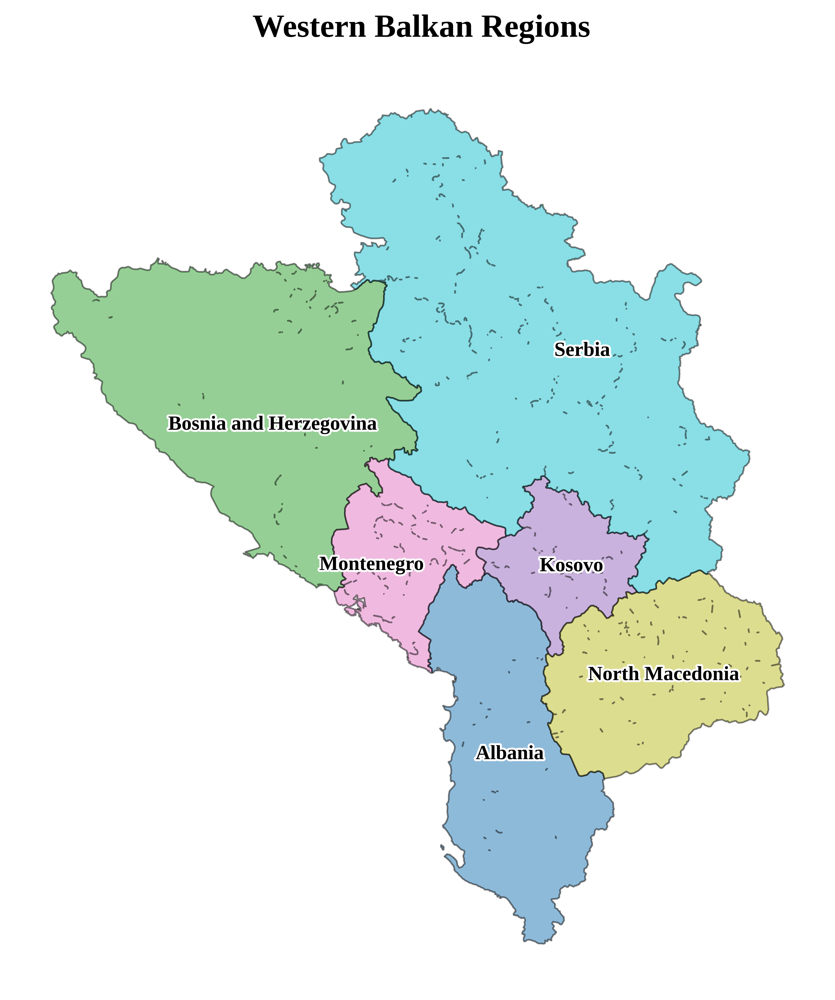

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

fig, ax = plt.subplots(figsize=(12, 7))
fig.suptitle(f" {country_name}", fontsize=16, fontweight='bold')

all_boundary_plot.plot(
    column="Country",
    categorical=True,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.5,
    ax=ax
)

for _, row in all_boundary_plot.iterrows():
    point = row.geometry.representative_point()
    txt = ax.annotate(
        row["Country"],
        xy=(point.x, point.y),
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="black"
    )
    txt.set_path_effects([
        pe.withStroke(linewidth=2, foreground="white")
    ])

ax.set_axis_off()
plt.tight_layout()
plt.savefig(f"{vis_save_to_root}/{country_name}_map.png")

In [14]:
combined_datahandler.save_image(
    f"{vis_save_to_root}/{country_name}_map.png",
    key=f"country_map_{country_kwd}",
    title=f"{country_name} regions map",
)

  └> RESource.hdf5_handler| 🖼️ Image saved to 'LandAnalytics/images/country_map_WesternBalkanRegions' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


- Create cells' instance for plotting (CRS-m)

In [15]:
if all_cells_gdf.crs != CRS_m:
    all_cells_plot = all_cells_gdf.to_crs(CRS_m)
else:
    all_cells_plot = all_cells_gdf

## Corine Land Cover

- Load CLC raster config to extract file name and other attributes

In [16]:
for raster in cfg.get('lands').get('CORINE').get('raster_types'):
    if raster['name']=='CORINE_land_cover':
        CLC_raster_cfg=raster

- Create a WB6 clipped (to geom) raster for plotting purpose. Our main workflow gives Country specific rasters.

 > Clip Raster to WB6 boundary (otherwise raster distribution will show wrong numbers)

In [17]:
CLC_source_raster_path=Path(ROOT/f"{CLC_raster_cfg['root']}/{CLC_raster_cfg['raster']}")

 - Clip CLC to Wb6 | Method 1
   - Load complete CLC data, use rio clip with reprojected (CRS_m) boundary  

!!! METHOD 1: Provides error and missing classes due to clipping logic

In [18]:
with rxr.open_rasterio(CLC_source_raster_path, masked=True) as source:
    source_boundary = all_boundary_plot.to_crs(source.rio.crs)
    CLC_da = source.rio.clip_box(*source_boundary.total_bounds).squeeze(drop=True).load()

In [19]:
# Ensure same CRS
# if WB6_boundary_dissolved_reproj.crs != CLC_da.rio.crs:
#     WB6_boundary_dissolved_reproj = WB6_boundary_dissolved_reproj.to_crs(CLC_da.rio.crs)

# Clip raster to boundary
# CLC_raster_WB6_da = CLC_da.rio.clip(WB6_boundary_dissolved_reproj.geometry,
#                                     # WB6_boundary_dissolved_reproj.crs,
#                                     drop=False,
#                                     invert=False,
#                                     all_touched=True)

 - Clip CLC to Wb6 | Method 2 (if more alteration necessary)
   - More Control to alter the resolution and CRS 

In [20]:
CLC_regional_raster_path = lands.clip_to_boundary_and_resample_raster(in_raster_config= CLC_raster_cfg,
                                           boundary_name=country_kwd,
                                           boundary=all_boundary_plot,
                                           CRS_meters=CRS_m,
                                           source_raster_path=CLC_source_raster_path,
                                           output_dir=results_save_to_root / 'intermediate',
                                           )

In [21]:
CLC_raster_regional_da=utils.get_raster_da(CLC_regional_raster_path)

✅ Loaded DataArray: U2018_CLC2018_V2020_20u1_clipped_WesternBalkanRegions.tif
   ├─ shape: (7175, 6301)
   ├─ CRS: EPSG:3035
   └─ res: (100.0, -100.0)


In [22]:
utils.check_raster_classes(CLC_da,CLC_raster_regional_da,all_boundary_plot)

--- Raster Integrity Report ---
Unique classes in Geographic Extent: 44
Unique classes in Clipped Result:    44
✅ Rigor Check Passed: No classes were lost during the geometric clip.


- Load Legends and Raster layers attributes from config

In [23]:
CLC_legends=pd.read_csv(ROOT/"src/RESource/assets/legends/CLC_2018_legend.csv")
class_inclusion_layers:dict=cfg.get('lands').get('CORINE').get('raster_types')[0]['class_inclusion']

- Check summary of existing sites

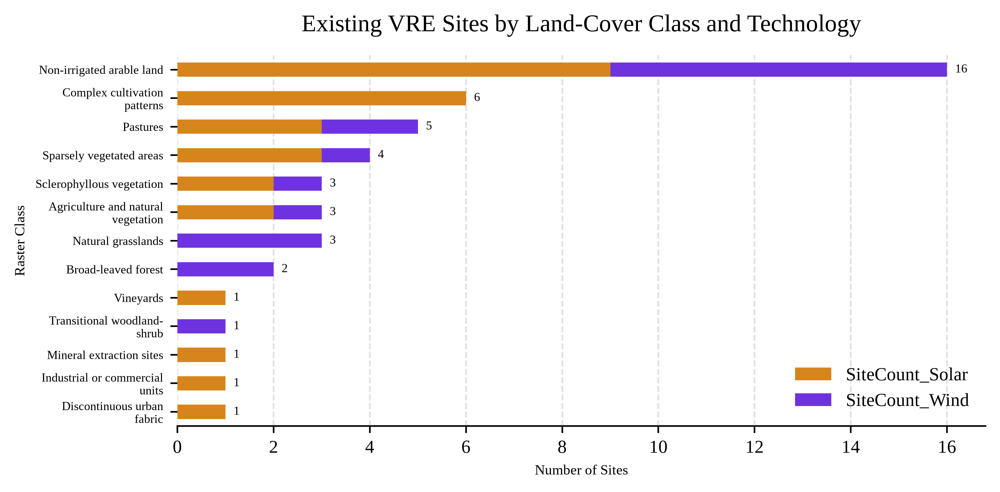

In [24]:
existing_VREs_gdf_with_landcover,existing_VREs_summary = lands.assign_raster_class_to_points(
    gdf=existing_VREs_gdf,
    raster_da=CLC_raster_regional_da,
    legend_df=CLC_legends,
    class_col_name="CLC_landcover",
    resource_type_col_name='Technology'
)

vis.plot_vre_sites_by_landcover(
    df=existing_VREs_summary,
    class_col="CLC_landcover_description",
    count_prefix="SiteCount_",
    title="Existing VRE Sites by Land-Cover Class and Technology",
    figsize=(7, 3.5),
    wrap_width=25,
    fontsize=6,
    colors=["#d6851c", "#6f32e0"],
    save_to=vis_save_to_root/f"existing_VREs_by_landcover_{country_kwd}.png"
)


In [25]:
combined_datahandler.to_store(existing_VREs_summary, "LandAnalytics/existing_VREs_by_CLC_landcover")
combined_datahandler.save_image(
    vis_save_to_root / f"existing_VREs_by_landcover_{country_kwd}.png",
    key="existing_VREs_by_landcover",
    title="Existing VRE sites by CORINE land-cover class and technology",
)

  └> RESource.hdf5_handler|💾 Data (GeoDataFrame/DataFrame) saved to /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5 with key 'LandAnalytics/existing_VREs_by_CLC_landcover'
  └> RESource.hdf5_handler| 🖼️ Image saved to 'LandAnalytics/images/existing_VREs_by_landcover' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


✅ Saved figure: /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/figures/CLC_class_distribution_WesternBalkanRegions.png


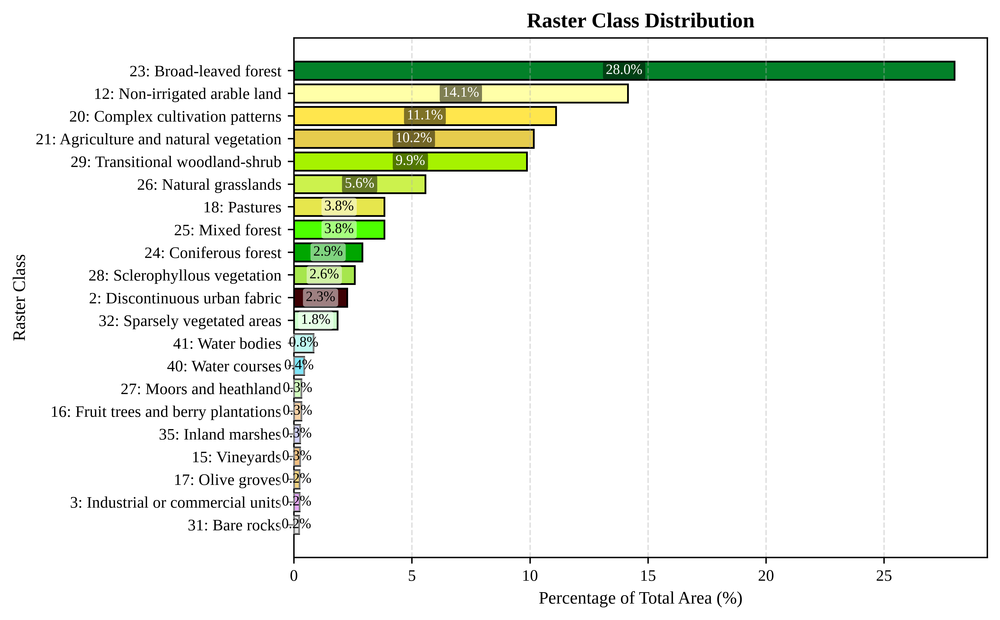

🧮 Excluding classes: [0] | Applied threshold: 0.2%


In [26]:
LandCover_CLC_class_distribution=lands.plot_raster_class_distribution(CLC_raster_regional_da,
                                     CLC_legends,
                                     show=True,
                                     figsize=(8,5),
                                     save_path=vis_save_to_root/f'CLC_class_distribution_{country_kwd}.png',
                                     pct_threshold=0.2)

In [27]:
combined_datahandler.to_store(LandCover_CLC_class_distribution, "LandAnalytics/CLC_class_distribution")
combined_datahandler.save_image(
    vis_save_to_root / f"CLC_class_distribution_{country_kwd}.png",
    key="CLC_class_distribution",
    title="CORINE land-cover class distribution",
)

  └> RESource.hdf5_handler|💾 Data (GeoDataFrame/DataFrame) saved to /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5 with key 'LandAnalytics/CLC_class_distribution'
  └> RESource.hdf5_handler| 🖼️ Image saved to 'LandAnalytics/images/CLC_class_distribution' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


- Define layers for plotting

In [28]:
layers_included:dict=CLC_raster_cfg['class_inclusion']

- Plot CLC + Existing VREs + Boundaries

✅ Raster clipped to boundary 'Country' region, shape: (7175, 6301)
 └> Reprojecting VRE GeoDataFrames to target CRS: EPSG:3035
 └> ⚠️ 'wind_turbine_capacity' not found. Using constant marker size = 1.0.
 └> No committed VREs data provided or GeoDataFrame is empty.
 └> Plotting existing and committed VREs.
└> Saved map with excluded overlay → /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/figures/CLC_WesternBalkanRegions_forNewVREsites.png


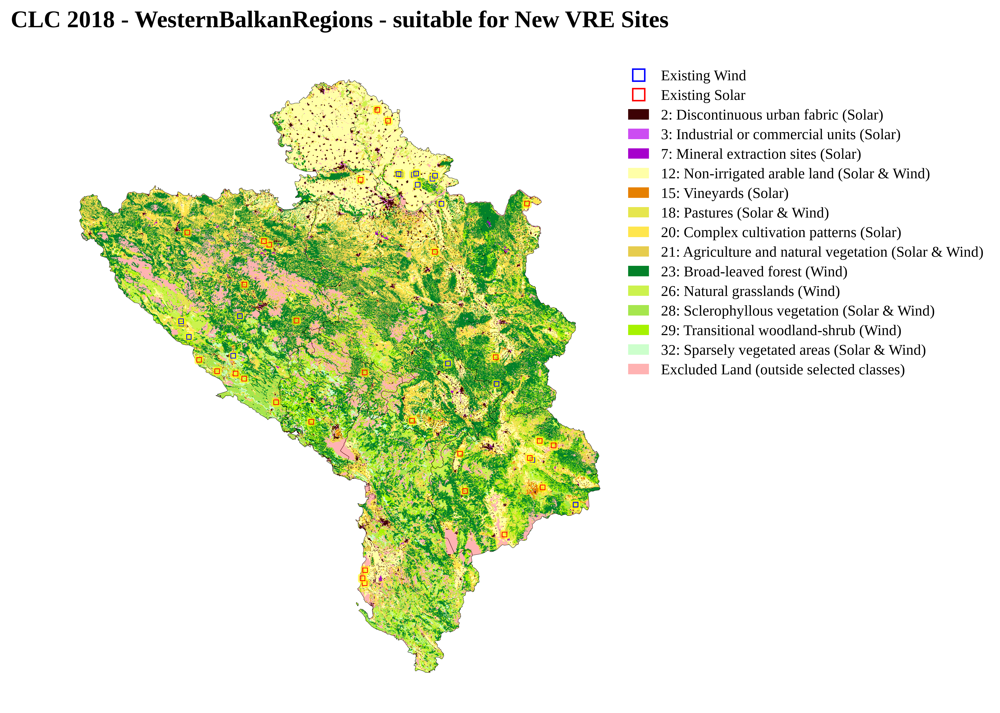

└> plot saved to: /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/figures/CLC_WesternBalkanRegions_forNewVREsites.png


In [29]:
classes_to_plot=layers_included # None , plots all layers

if classes_to_plot is None:
    title = "CLC 2018 - All Layers"
    save_to_path = vis_save_to_root/"CLC_AllLayers.png"
else:
    title = f"CLC 2018 - {country_kwd} - suitable for New VRE Sites"
    save_to_path = vis_save_to_root/f"CLC_{country_kwd}_forNewVREsites.png"

fig1,ax1,save_to1=vis.plot_developable_land_and_vres(
    target_crs=CRS_m,
    raster_data=CLC_raster_regional_da,
    raster_legends=CLC_legends,
    classes_to_plot=classes_to_plot, #layers,                 # <- all classes
    boundary=all_boundary_plot,
    existing_VREs_gdf=existing_VREs_gdf,
    vre_type_column="Technology",
    marker_scale_existing=10.0,
    figsize=(16, 9),
    dpi=500,
    marker_highlight_width=3,
    title=title,
    output_path=save_to_path,
    legend_anchor=(.98, .99),
    legend_fontsize=10
)

utils.print_update(level=1,message=f"plot saved to: {save_to_path}")

In [30]:
combined_datahandler.save_image(
    save_to1,
    key="CLC_developable_land_and_VREs",
    title=title,
)

  └> RESource.hdf5_handler| 🖼️ Image saved to 'LandAnalytics/images/CLC_developable_land_and_VREs' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


## GAEZ

Load the configured global source layers from the local FAO-GAEZ v4.0 LR archive and clip them to the combined boundary at their original resolution. The country-specific processed rasters do not cover the whole combined region. Source: FAO-GAEZ v4.0, 2021.

**Rerun the GAEZ cells below:** previously saved outputs may reflect a single country's raster.

### Terrain

In [31]:
missing_regions = sorted(set(regions) - set(combined_store))
if missing_regions:
    raise ValueError(f"Cannot plot the complete GAEZ region: missing stores for {missing_regions}")
GAEZ_archive_path = ROOT / cfg['lands']['GAEZ']['root'] / cfg['lands']['GAEZ']['zip_file']
GAEZ_terrain_raster_legends=pd.read_csv(ROOT/"src/RESource/assets/legends/gaez_terrains_legend.csv")
GAEZ_terrain_cfg= next((item for item in cfg.get('lands').get('GAEZ').get('raster_types') if 'terrain_resources' in item.get('name', '')), None)

- Load and clip the source raster to the combined boundary

In [32]:
GAEZ_terrain_raster_da_clipped = load_gaez_raster(
    GAEZ_archive_path,
    f"{GAEZ_terrain_cfg['zip_extract_direct']}/{GAEZ_terrain_cfg['raster']}",
    all_boundary_dissolved,
)

- Review class distributions

✅ Saved figure: /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/figures/GAEZ_terrains_class_distribution_WesternBalkanRegions.png


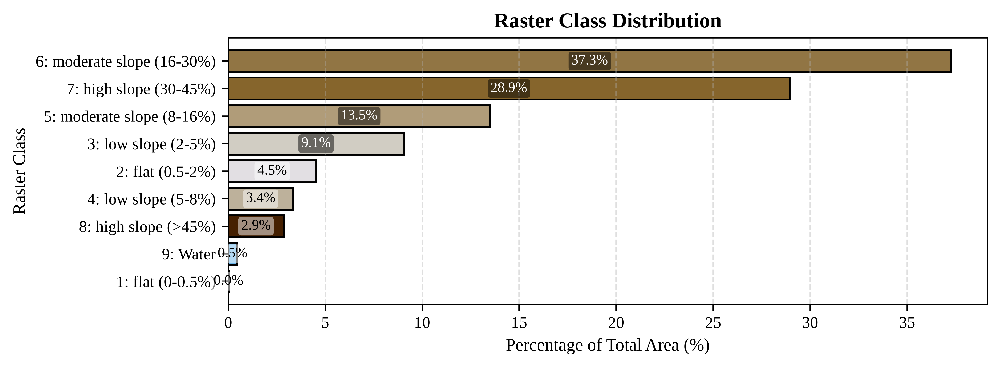

🧮 Excluding classes: [0] | Applied threshold: 0.0%


,class,Percentage,description,color,label
0,1,0.030202,flat (0-0.5%),#eeefedff,1: flat (0-0.5%)
8,9,0.453035,Water,#6bb5eaff,9: Water
7,8,2.869224,high slope (>45%),#452001ff,8: high slope (>45%)
3,4,3.352461,low slope (5-8%),#bdb19bff,4: low slope (5-8%)
1,2,4.530353,flat (0.5-2%),#e2dfe3ff,2: flat (0.5-2%)
2,3,9.060707,low slope (2-5%),#d1cdc3ff,3: low slope (2-5%)
4,5,13.500453,moderate slope (8-16%),#b09c79ff,5: moderate slope (8-16%)
6,7,28.933857,high slope (30-45%),#86652cff,7: high slope (30-45%)
5,6,37.269707,moderate slope (16-30%),#917544ff,6: moderate slope (16-30%)


In [33]:
lands.plot_raster_class_distribution(GAEZ_terrain_raster_da_clipped,
                                     GAEZ_terrain_raster_legends,
                                     show=True,
                                     figsize=(8,3),
                                     save_path=vis_save_to_root/f'GAEZ_terrains_class_distribution_{country_kwd}.png')


In [34]:
combined_datahandler.save_image(
    vis_save_to_root / f'GAEZ_terrains_class_distribution_{country_kwd}.png',
    key="GAEZ_terrains_class_distribution",
    title="GAEZ terrain class distribution",
)

  └> RESource.hdf5_handler| 🖼️ Image saved to 'LandAnalytics/images/GAEZ_terrains_class_distribution' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


- Review layers mapping to existing VREs

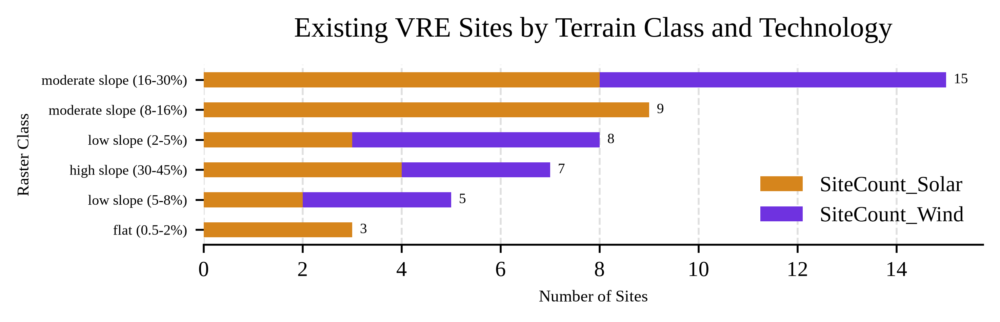

In [35]:
existing_VREs_gdf_with_terrains,terrains_summary = lands.assign_raster_class_to_points(
    gdf=existing_VREs_gdf,
    raster_da=GAEZ_terrain_raster_da_clipped,
    legend_df=GAEZ_terrain_raster_legends,
    class_col_name="GAEZ_terrain",
    resource_type_col_name='Technology'
)

vis.plot_vre_sites_by_landcover(
    df=terrains_summary,
    class_col="GAEZ_terrain_description",
    count_prefix="SiteCount_",
    title="Existing VRE Sites by Terrain Class and Technology",
    figsize=(6, 2),
    wrap_width=25,
    fontsize=6,
    colors=["#d6851c", "#6f32e0"],
    save_to=vis_save_to_root/f"existing_VREs_by_terrain_{country_kwd}.png"
)


In [36]:
combined_datahandler.to_store(terrains_summary, "LandAnalytics/existing_VREs_by_GAEZ_terrain")
combined_datahandler.save_image(
    vis_save_to_root / f"existing_VREs_by_terrain_{country_kwd}.png",
    key="existing_VREs_by_terrain",
    title="Existing VRE sites by GAEZ terrain class and technology",
)

  └> RESource.hdf5_handler|💾 Data (GeoDataFrame/DataFrame) saved to /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5 with key 'LandAnalytics/existing_VREs_by_GAEZ_terrain'
  └> RESource.hdf5_handler| 🖼️ Image saved to 'LandAnalytics/images/existing_VREs_by_terrain' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


- Define the layers to be plotted

In [37]:
import numpy as np
layers_excluded:dict=GAEZ_terrain_cfg['class_exclusion']

# Unique CLC codes in your clipped area
unique_classes = np.unique(GAEZ_terrain_raster_da_clipped.values[~np.isnan(GAEZ_terrain_raster_da_clipped.values)])

layers_included = {
    tech: [c for c in unique_classes if c not in layers_excluded[tech] and c != 0]
    for tech in ['solar', 'wind']
}

- Plot GAEZ Terrain with defined layers and existing VREs

✅ Raster clipped to boundary 'Country' region, shape: (90, 79)


 └> Reprojecting VRE GeoDataFrames to target CRS: EPSG:3035
 └> ⚠️ 'wind_turbine_capacity' not found. Using constant marker size = 1.0.
 └> No committed VREs data provided or GeoDataFrame is empty.
 └> Plotting existing and committed VREs.
└> Saved map with excluded overlay → /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/figures/GAEZ_terrains_WesternBalkanRegions_forNewVREsites.png


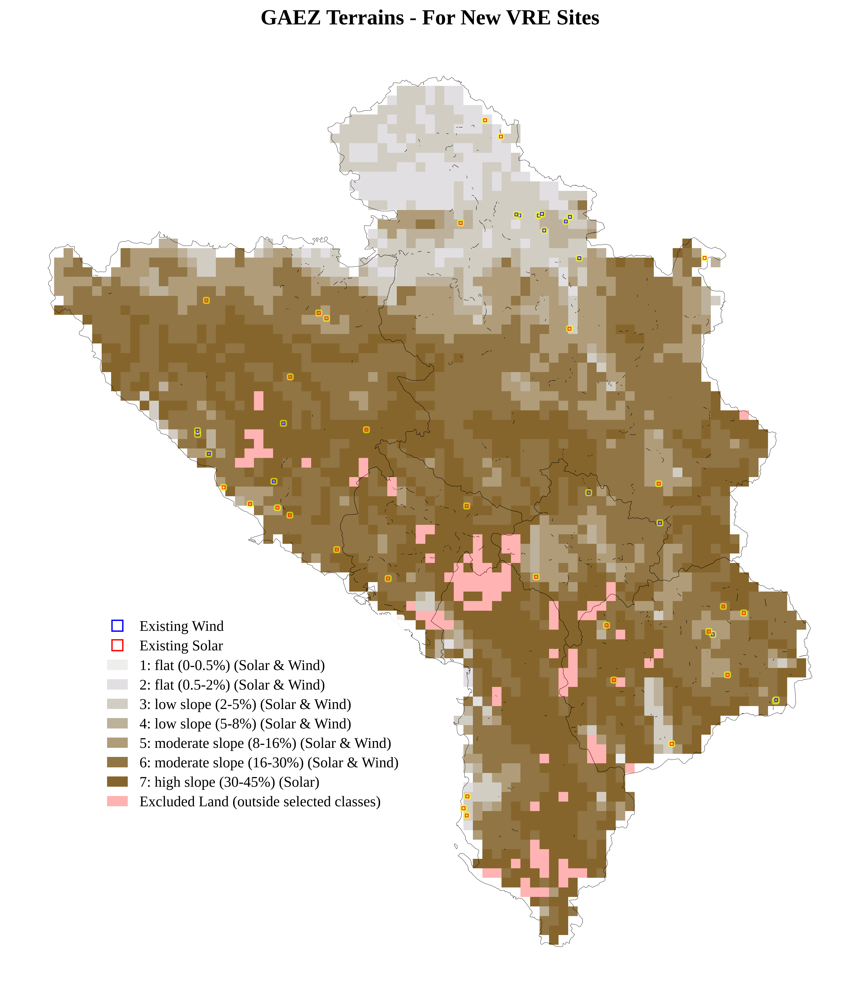

└> plot saved to: /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/figures/GAEZ_terrains_WesternBalkanRegions_forNewVREsites.png


In [38]:
classes_to_plot = layers_included # layers_included #None , plots all layers

if classes_to_plot is None:
    GAEZ_terrain_save_to_path=vis_save_to_root/f"GAEZ_terrains_{country_kwd}_allLayers.png"
    title = "GAEZ Terrains - All Layers"
else:
# Update DOC contents (if needed)
    GAEZ_terrain_save_to_path=vis_save_to_root/f"GAEZ_terrains_{country_kwd}_forNewVREsites.png"
    title = "GAEZ Terrains - For New VRE Sites"

fig2,ax2,save_to2=vis.plot_developable_land_and_vres(
    target_crs=CRS_m,
    raster_data=GAEZ_terrain_raster_da_clipped,
    raster_legends=GAEZ_terrain_raster_legends,
    classes_to_plot=classes_to_plot, #layers_included,                 # <- all classes
    boundary=all_boundary_plot,
    existing_VREs_gdf=existing_VREs_gdf,
    vre_type_column="Technology",
    marker_scale_existing=5.0,
    legend_fontsize=11,
    title=title,
    output_path=GAEZ_terrain_save_to_path,
    legend_anchor=(.1, .4),
    marker_highlight_width=3,
)
utils.print_update(level=1,message=f"plot saved to: {GAEZ_terrain_save_to_path}")

In [39]:
combined_datahandler.save_image(
    save_to2,
    key="GAEZ_terrain_developable_land_and_VREs",
    title=title,
)

  └> RESource.hdf5_handler| 🖼️ Image saved to 'LandAnalytics/images/GAEZ_terrain_developable_land_and_VREs' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


### Exclusion

In [40]:
GAEZ_exclusion_raster_legends=pd.read_csv(ROOT/"src/RESource/assets/legends/gaez_exclusion_legend.csv")
GAEZ_exclusion_cover_cfg= next((item for item in cfg.get('lands').get('GAEZ').get('raster_types') if 'exclusion_areas' in item.get('name', '')), None)

- Load and clip the source raster to the combined boundary

In [41]:
GAEZ_exclusion_raster_data_clipped = load_gaez_raster(
    GAEZ_archive_path,
    f"{GAEZ_exclusion_cover_cfg['zip_extract_direct']}/{GAEZ_exclusion_cover_cfg['raster']}",
    all_boundary_dissolved,
)

- Plot Class Distribution

✅ Saved figure: /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/figures/GAEZ_Exclusion_class_distribution_WesternBalkanRegions.png


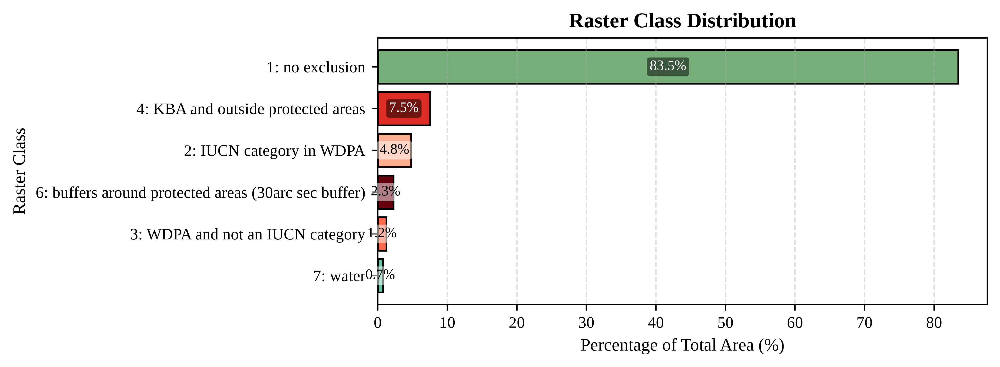

🧮 Excluding classes: [0] | Applied threshold: 0.0%


,class,Percentage,description,color,label
5,7,0.717141,water,#66c2a5,7: water
2,3,1.220652,WDPA and not an IUCN category,#fb6a4a,3: WDPA and not an IUCN category
4,6,2.263381,buffers around protected areas (30arc sec buffer),#67000d,6: buffers around protected areas (30arc sec b...
1,2,4.811803,IUCN category in WDPA,#fcae91,2: IUCN category in WDPA
3,4,7.504864,KBA and outside protected areas,#de2d26,4: KBA and outside protected areas
0,1,83.482158,no exclusion,#75ae79ff,1: no exclusion


In [42]:
lands.plot_raster_class_distribution(GAEZ_exclusion_raster_data_clipped,
                                     GAEZ_exclusion_raster_legends,
                                     show=True,
                                     figsize=(8,3),
                                     save_path=vis_save_to_root/f'GAEZ_Exclusion_class_distribution_{country_kwd}.png')

In [43]:
combined_datahandler.save_image(
    vis_save_to_root / f'GAEZ_Exclusion_class_distribution_{country_kwd}.png',
    key="GAEZ_exclusion_class_distribution",
    title="GAEZ exclusion class distribution",
)

  └> RESource.hdf5_handler| 🖼️ Image saved to 'LandAnalytics/images/GAEZ_exclusion_class_distribution' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


- Review existing sites and excluded lands

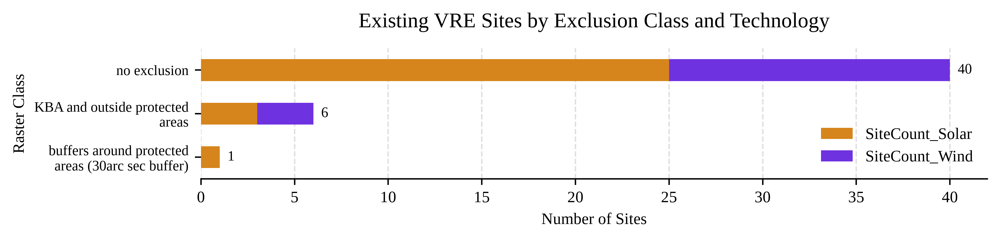

In [44]:
existing_VREs_gdf_with_exclusions,exclusions_summary = lands.assign_raster_class_to_points(
    gdf=existing_VREs_gdf,
    raster_da=GAEZ_exclusion_raster_data_clipped,
    legend_df=GAEZ_exclusion_raster_legends,
    class_col_name="GAEZ_exclusion",
    resource_type_col_name='Technology'
)

vis.plot_vre_sites_by_landcover(
    df=exclusions_summary,
    class_col="GAEZ_exclusion_description",
    count_prefix="SiteCount_",
    title="Existing VRE Sites by Exclusion Class and Technology",
    figsize=(8, 2),
    wrap_width=25,
    fontsize=8,
    colors=["#d6851c", "#6f32e0"],
    save_to=vis_save_to_root/f"existing_VREs_by_exclusions_{country_kwd}.png"
)

In [45]:
combined_datahandler.to_store(exclusions_summary, "LandAnalytics/existing_VREs_by_GAEZ_exclusion")
combined_datahandler.save_image(
    vis_save_to_root / f"existing_VREs_by_exclusions_{country_kwd}.png",
    key="existing_VREs_by_exclusions",
    title="Existing VRE sites by GAEZ exclusion class and technology",
)

  └> RESource.hdf5_handler|💾 Data (GeoDataFrame/DataFrame) saved to /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5 with key 'LandAnalytics/existing_VREs_by_GAEZ_exclusion'
  └> RESource.hdf5_handler| 🖼️ Image saved to 'LandAnalytics/images/existing_VREs_by_exclusions' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


- Define layers to be plotted

In [46]:
layers_excluded:dict=GAEZ_exclusion_cover_cfg['class_exclusion']

# Unique GAEZ exclusion codes in the combined boundary
unique_classes = np.unique(GAEZ_exclusion_raster_data_clipped.values[~np.isnan(GAEZ_exclusion_raster_data_clipped.values)])

layers_included = {
    tech: [c for c in unique_classes if c not in layers_excluded[tech] and c != 0]
    for tech in ['solar', 'wind']
}

- Plot

✅ Raster clipped to boundary 'Country' region, shape: (902, 793)


 └> Reprojecting VRE GeoDataFrames to target CRS: EPSG:3035
 └> ⚠️ 'wind_turbine_capacity' not found. Using constant marker size = 1.0.
 └> No committed VREs data provided or GeoDataFrame is empty.
 └> Plotting existing and committed VREs.
└> Saved map with excluded overlay → /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/figures/GAEZ_exclusion_WesternBalkanRegions_forNewVREsites.png


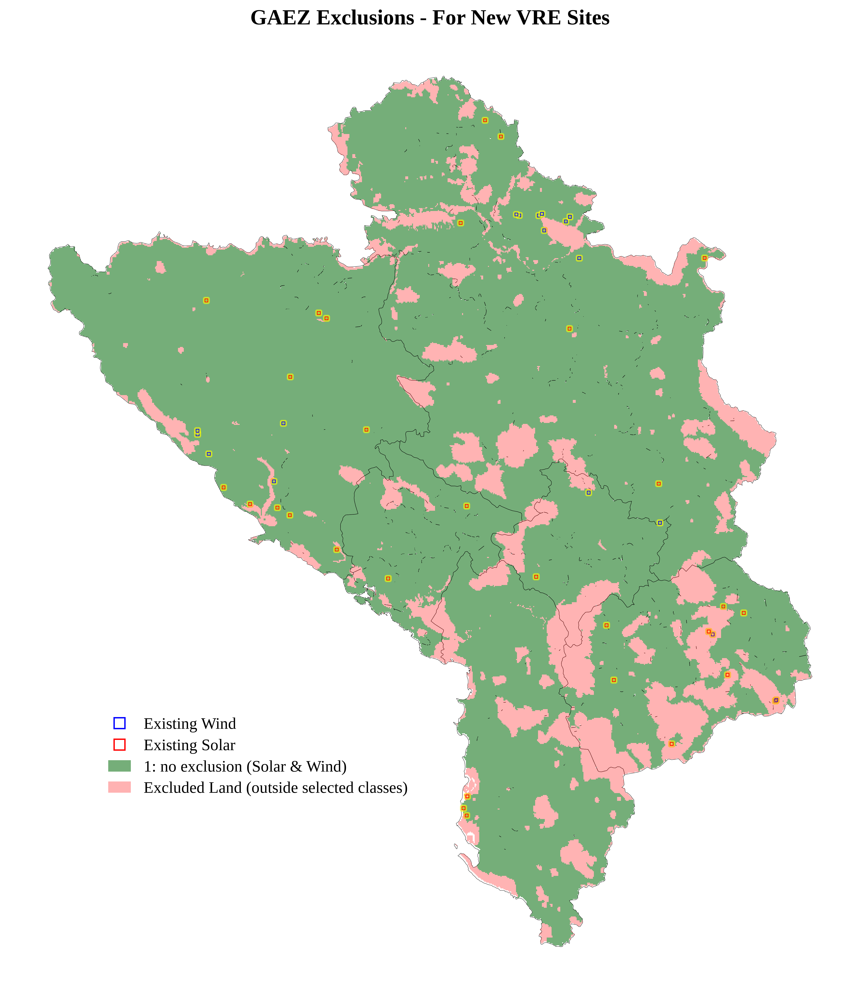

└> plot saved to: /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/figures/GAEZ_exclusion_WesternBalkanRegions_forNewVREsites.png


In [47]:
classes_to_plot = layers_included  #None , plots all layers

if classes_to_plot is None:
    GAEZ_exclusion_save_to_path=vis_save_to_root/f"GAEZ_exclusion_{country_kwd}_allLayers.png"
    title = "GAEZ Exclusions - All Layers"
else:
# Update DOC contents (if needed)
    GAEZ_exclusion_save_to_path=vis_save_to_root/f"GAEZ_exclusion_{country_kwd}_forNewVREsites.png"
    title = "GAEZ Exclusions - For New VRE Sites"

fig3,ax3,save_to3=vis.plot_developable_land_and_vres(
    target_crs=CRS_m,
    raster_data=GAEZ_exclusion_raster_data_clipped,
    raster_legends=GAEZ_exclusion_raster_legends,
    classes_to_plot=classes_to_plot, #layers_included,                 # <- all classes
    boundary=all_boundary_plot,
    existing_VREs_gdf=existing_VREs_gdf,
    vre_type_column="Technology",
    marker_scale_existing=5.0,
    figsize=(16, 9),
    dpi=500,
    legend_fontsize=12,
    title=title,
    output_path=GAEZ_exclusion_save_to_path,
    legend_anchor=(.1, .3),
    marker_highlight_width=3,
)
utils.print_update(level=1,message=f"plot saved to: {GAEZ_exclusion_save_to_path}")

In [48]:
combined_datahandler.save_image(
    save_to3,
    key="GAEZ_exclusion_developable_land_and_VREs",
    title=title,
)

  └> RESource.hdf5_handler| 🖼️ Image saved to 'LandAnalytics/images/GAEZ_exclusion_developable_land_and_VREs' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5


# Grid

In [49]:
all_lines=[combined_store[region]['lines'] for region in combined_store]
all_lines = gpd.GeoDataFrame(pd.concat(all_lines, ignore_index=True), crs=all_lines[0].crs)

In [50]:
# Convert to numeric
all_lines['voltage_kv'] = pd.to_numeric(all_lines['voltage'], errors='coerce') / 1000

# Define voltage bins
bins = [0, 12, 25, 132, 220, float("inf")]
labels = ["<12 kV", "12–25 kV", "25–132 kV", "132–220 kV", "≥220 kV"]
all_lines['voltage_class'] = pd.cut(all_lines['voltage_kv'], bins=bins, labels=labels, right=False)


- Plot gird

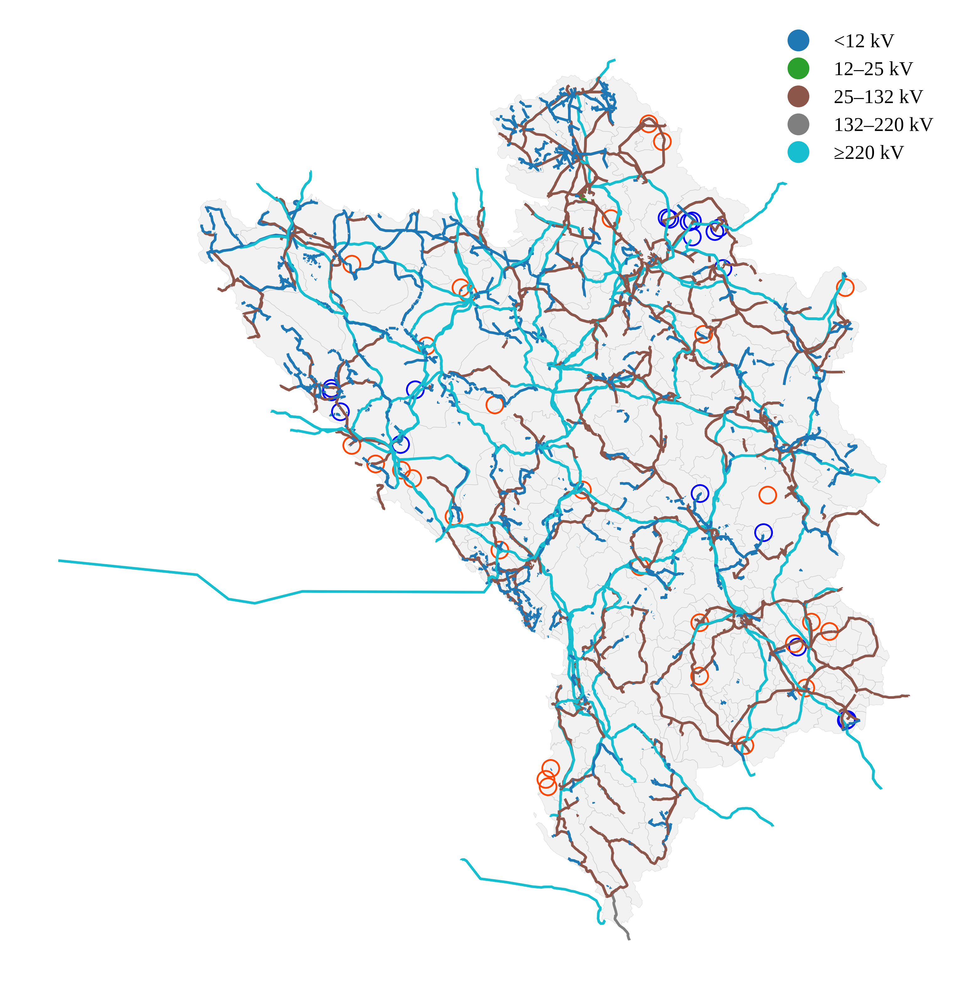

In [51]:
from matplotlib.patches import Patch
ax=all_boundary_gdf.plot(edgecolor='black', facecolor='grey', linewidth=0.2, figsize=(10, 8),alpha=0.1)

ax.set_axis_off()

if existing_VREs_gdf is not None and not existing_VREs_gdf.empty:

    existing_VREs_gdf[existing_VREs_gdf['Technology'].str.lower()=='wind'].plot(ax=ax, color='None', edgecolor='blue',markersize=60, linewidth=0.8,marker='o', label='Existing VREs',alpha=1,zorder=2)

    # Add legend for existing wind (purple)
    legend_handles = [Patch(facecolor='none', edgecolor='purple', label='Existing Wind', alpha=1)]
    ax.legend(handles=legend_handles, loc='upper left', fontsize=8, frameon=False)

    existing_VREs_gdf[existing_VREs_gdf['Technology'].str.lower()=='solar'].plot(ax=ax, color='None', edgecolor='orangered',markersize=60,linewidth=0.8, marker='o', label='Existing VREs',alpha=1,zorder=2)
all_lines.plot('voltage_class',ax=ax, figsize=(10, 8), legend=True)

plt.savefig(vis_save_to_root/f"WB6_existing_VREs_and_lines_{country_kwd}.png", dpi=500, bbox_inches='tight')

In [52]:
lines_for_store = all_lines.assign(voltage_class=all_lines['voltage_class'].astype(object))
combined_datahandler.to_store(lines_for_store, "LandAnalytics/transmission_lines_combined")
combined_datahandler.save_image(
    vis_save_to_root / f"WB6_existing_VREs_and_lines_{country_kwd}.png",
    key="grid_lines_and_existing_VREs",
    title="Transmission grid and existing VRE sites",
)

  └> RESource.hdf5_handler|💾 Data (GeoDataFrame/DataFrame) saved to /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5 with key 'LandAnalytics/transmission_lines_combined'
  └> RESource.hdf5_handler| 🖼️ Image saved to 'LandAnalytics/images/grid_lines_and_existing_VREs' in /local-scratch/localhome/mei3/eliasinul/work/RESource/results/WesternBalkanRegions/VRElow/Combined_lands_20261116_165906_037839/resources_WesternBalkanRegions_Combined_VRElow_2025_20261116.h5
